# Notebook 21: Multi-Label Domain Categorization Dataset, Model & Evaluation
**AI-Powered Student Achievement Intelligence Platform — Member 1 (NLP & Semantic Intelligence)**

## 1. Executive Summary & Objective
This notebook develops, evaluates, and documents the **Multi-Label Domain Categorization Subsystem** (Step 10).

### Key Architectural Separation:
- **Single-Label Primary Classification (Step 5):** Predicts exactly one primary achievement category from a 14-class taxonomy (`CERTIFICATION`, `HACKATHON`, `INTERNSHIP`, `RESEARCH_PUBLICATION`, etc.). Represents the *form* of achievement.
- **Multi-Label Domain Categorization (Step 10):** Predicts zero or more applicable domain tags from an orthogonal 10-tag taxonomy representing the *technical and academic disciplines* involved.

### 10 Domain Tags Taxonomy:
1. `lbl_domain_ai`: Artificial Intelligence
2. `lbl_domain_ml`: Machine Learning
3. `lbl_domain_nlp`: Natural Language Processing
4. `lbl_domain_cv`: Computer Vision
5. `lbl_domain_security`: Cybersecurity & Privacy
6. `lbl_domain_systems`: Systems, Cloud & Architecture
7. `lbl_domain_web`: Web Development & APIs
8. `lbl_domain_data`: Data Engineering & Analytics
9. `lbl_domain_hardware`: Hardware & IoT
10. `lbl_domain_other`: Other domain (Non-computing)

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

from src.nlp.categorization import DOMAIN_TAGS, DOMAIN_TAG_NAMES, AchievementCategorizer, CategorizationResult
from src.nlp.categorization_dataset import generate_categorization_dataset

print(f"Total Domain Tags: {len(DOMAIN_TAGS)}")
for tag in DOMAIN_TAGS:
    print(f"  - {tag}: {DOMAIN_TAG_NAMES[tag]}")

Total Domain Tags: 10
  - lbl_domain_ai: Artificial intelligence
  - lbl_domain_ml: Machine learning
  - lbl_domain_nlp: Natural language processing
  - lbl_domain_cv: Computer vision
  - lbl_domain_security: Security
  - lbl_domain_systems: Systems & Cloud
  - lbl_domain_web: Web and application
  - lbl_domain_data: Data engineering and analytics
  - lbl_domain_hardware: Hardware and embedded systems
  - lbl_domain_other: Other domain (Non-computing)


## 2. Dataset Loading & Multi-Label Tag Distribution
Load `data/processed/achievement_categorization_dataset.csv` (1,540 frozen records).
Inspect tag prevalence, tag co-occurrence rates, and tag counts per record.

In [2]:
dataset_path = Path("data/processed/achievement_categorization_dataset.csv")
df = pd.read_csv(dataset_path)
print(f"Loaded dataset: {len(df)} records, {len(df.columns)} columns")

# Compute tag prevalence
prevalence = {}
for t in DOMAIN_TAGS:
    col = f"tag_{t}"
    cnt = int(df[col].sum())
    pct = (cnt / len(df)) * 100.0
    prevalence[t] = {"count": cnt, "percentage": pct, "name": DOMAIN_TAG_NAMES[t]}

prev_df = pd.DataFrame.from_dict(prevalence, orient="index")
print("\n--- Multi-Label Tag Prevalence Across 1,540 Records ---")
print(prev_df[["name", "count", "percentage"]].to_string())

# Tag count per record distribution
tag_counts = df["tag_count"].value_counts().sort_index()
print("\n--- Tag Count Distribution (Number of Tags per Achievement) ---")
for num_tags, freq in tag_counts.items():
    pct = (freq / len(df)) * 100.0
    print(f"  {num_tags} tags: {freq:4d} records ({pct:5.1f}%)")

Loaded dataset: 1540 records, 21 columns

--- Multi-Label Tag Prevalence Across 1,540 Records ---
                                               name  count  percentage
lbl_domain_ai               Artificial intelligence    637   41.363636
lbl_domain_ml                      Machine learning    265   17.207792
lbl_domain_nlp          Natural language processing    133    8.636364
lbl_domain_cv                       Computer vision     93    6.038961
lbl_domain_security                        Security    192   12.467532
lbl_domain_systems                  Systems & Cloud    643   41.753247
lbl_domain_web                  Web and application    350   22.727273
lbl_domain_data      Data engineering and analytics    560   36.363636
lbl_domain_hardware   Hardware and embedded systems    532   34.545455
lbl_domain_other       Other domain (Non-computing)    220   14.285714

--- Tag Count Distribution (Number of Tags per Achievement) ---
  0 tags:  130 records (  8.4%)
  1 tags:  420 records (

## 3. Split Integrity & Zero ID Leakage Verification
Verify that train (1,078), validation (231), and test (231) splits match the master dataset splits
and have strictly 0 overlapping IDs.

In [3]:
train_df = pd.read_csv("data/splits/categorization_train.csv")
val_df = pd.read_csv("data/splits/categorization_validation.csv")
test_df = pd.read_csv("data/splits/categorization_test.csv")

print(f"Train samples: {len(train_df)}")
print(f"Val samples:   {len(val_df)}")
print(f"Test samples:  {len(test_df)}")
assert len(train_df) + len(val_df) + len(test_df) == 1540

train_ids = set(train_df["achievement_id"])
val_ids = set(val_df["achievement_id"])
test_ids = set(test_df["achievement_id"])

leakage_train_val = len(train_ids.intersection(val_ids))
leakage_train_test = len(train_ids.intersection(test_ids))
leakage_val_test = len(val_ids.intersection(test_ids))

print(f"Leakage Train-Val:  {leakage_train_val}")
print(f"Leakage Train-Test: {leakage_train_test}")
print(f"Leakage Val-Test:   {leakage_val_test}")
assert leakage_train_val == 0 and leakage_train_test == 0 and leakage_val_test == 0

# Check master split alignment
master_train = pd.read_csv("data/splits/train.csv")
master_val = pd.read_csv("data/splits/validation.csv")
master_test = pd.read_csv("data/splits/test.csv")

assert train_ids == set(master_train["achievement_id"])
assert val_ids == set(master_val["achievement_id"])
assert test_ids == set(master_test["achievement_id"])
print("[OK] Split integrity and master alignment verified 100%.")

Train samples: 1078
Val samples:   231
Test samples:  231
Leakage Train-Val:  0
Leakage Train-Test: 0
Leakage Val-Test:   0
[OK] Split integrity and master alignment verified 100%.


## 4. Multi-Label Categorizer Architecture & Training
The categorizer uses **TF-IDF Feature Extraction** with sublinear term frequency and word+bigram features,
combined with **Binary Relevance Logistic Regression** with per-tag decision threshold optimization ($T_k$)
calibrated on the validation split.

In [4]:
# Load existing production model artifact
model_path = Path("models/achievement_categorizer_v1.0.1.joblib")
categorizer = AchievementCategorizer.load(model_path)

print(f"Model Version: {categorizer.model_version}")
print(f"Vocabulary Features: {len(categorizer.vectorizer.get_feature_names_out())}")
print("\nValidation-Calibrated Decision Thresholds per Tag:")
for t in DOMAIN_TAGS:
    thresh = categorizer.thresholds.get(t, 0.50)
    val_f1 = categorizer.metadata.get("validation_f1_per_tag", {}).get(t, 0.0)
    print(f"  {t:22s} Threshold: {thresh:.3f} | Val F1: {val_f1:.4f}")

Model Version: 1.0.1
Vocabulary Features: 5000

Validation-Calibrated Decision Thresholds per Tag:
  lbl_domain_ai          Threshold: 0.400 | Val F1: 0.7665
  lbl_domain_ml          Threshold: 0.625 | Val F1: 0.4857
  lbl_domain_nlp         Threshold: 0.575 | Val F1: 0.5000
  lbl_domain_cv          Threshold: 0.600 | Val F1: 0.5294
  lbl_domain_security    Threshold: 0.600 | Val F1: 0.5405
  lbl_domain_systems     Threshold: 0.500 | Val F1: 0.7656
  lbl_domain_web         Threshold: 0.550 | Val F1: 0.5490
  lbl_domain_data        Threshold: 0.425 | Val F1: 0.6977
  lbl_domain_hardware    Threshold: 0.400 | Val F1: 0.7042
  lbl_domain_other       Threshold: 0.250 | Val F1: 1.0000


## 5. Evaluation on Held-Out Test Split (231 Records)
Evaluate predictions on the unseen test split.
Compute Hamming Loss, Exact Match ratio, Subset Accuracy, and per-tag Precision, Recall, and F1.

In [5]:
X_test = test_df["achievement_text"].tolist()
Y_test_true = np.zeros((len(test_df), len(DOMAIN_TAGS)), dtype=int)
for i, tag in enumerate(DOMAIN_TAGS):
    Y_test_true[:, i] = test_df[f"tag_{tag}"].values

# Run batch prediction
test_results = categorizer.predict_batch(X_test)
Y_test_pred = np.zeros((len(test_df), len(DOMAIN_TAGS)), dtype=int)

for row_idx, res in enumerate(test_results):
    for tag_name in res.predicted_tags:
        col_idx = DOMAIN_TAGS.index(tag_name)
        Y_test_pred[row_idx, col_idx] = 1

# Multi-label metrics
h_loss = hamming_loss(Y_test_true, Y_test_pred)
exact_match = np.mean(np.all(Y_test_true == Y_test_pred, axis=1))
micro_p = precision_score(Y_test_true, Y_test_pred, average="micro", zero_division=0)
micro_r = recall_score(Y_test_true, Y_test_pred, average="micro", zero_division=0)
micro_f1 = f1_score(Y_test_true, Y_test_pred, average="micro", zero_division=0)
macro_f1 = f1_score(Y_test_true, Y_test_pred, average="macro", zero_division=0)

print("=== HELD-OUT TEST EVALUATION METRICS ===")
print(f"  Hamming Loss:     {h_loss:.4f} (lower is better)")
print(f"  Exact Match Rate: {exact_match:.4f} ({exact_match*100:.1f}%)")
print(f"  Micro Precision:  {micro_p:.4f}")
print(f"  Micro Recall:     {micro_r:.4f}")
print(f"  Micro F1 Score:   {micro_f1:.4f}")
print(f"  Macro F1 Score:   {macro_f1:.4f}")

# Per-tag metrics table
per_tag_metrics = []
for i, tag in enumerate(DOMAIN_TAGS):
    y_true_tag = Y_test_true[:, i]
    y_pred_tag = Y_test_pred[:, i]
    p = precision_score(y_true_tag, y_pred_tag, zero_division=0)
    r = recall_score(y_true_tag, y_pred_tag, zero_division=0)
    f = f1_score(y_true_tag, y_pred_tag, zero_division=0)
    support = int(y_true_tag.sum())
    per_tag_metrics.append({
        "Tag": tag,
        "Name": DOMAIN_TAG_NAMES[tag],
        "Support": support,
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "F1": round(f, 4),
        "Threshold": categorizer.thresholds[tag],
    })

df_metrics = pd.DataFrame(per_tag_metrics)
print("\n=== Per-Tag Performance on Held-Out Test Split ===")
print(df_metrics[["Name", "Support", "Precision", "Recall", "F1", "Threshold"]].to_string(index=False))

=== HELD-OUT TEST EVALUATION METRICS ===
  Hamming Loss:     0.1922 (lower is better)
  Exact Match Rate: 0.3333 (33.3%)
  Micro Precision:  0.5687
  Micro Recall:     0.7551
  Micro F1 Score:   0.6487
  Macro F1 Score:   0.5640

=== Per-Tag Performance on Held-Out Test Split ===
                          Name  Support  Precision  Recall     F1  Threshold
       Artificial intelligence      100     0.6565  0.8600 0.7446      0.400
              Machine learning       35     0.4667  0.4000 0.4308      0.625
   Natural language processing       28     0.1667  0.1071 0.1304      0.575
               Computer vision       10     0.2143  0.3000 0.2500      0.600
                      Security       28     0.3333  0.5357 0.4110      0.600
               Systems & Cloud       95     0.6339  0.7474 0.6860      0.500
           Web and application       48     0.5574  0.7083 0.6239      0.550
Data engineering and analytics       90     0.5971  0.9222 0.7249      0.425
 Hardware and embedded sys

## 6. Evaluation on Manually Reviewed Gold Reference Subset (45 Samples)
Evaluate the categorizer on the 45-sample manually audited gold reference subset
(`data/annotations/categorization_reviewed_reference_samples.jsonl`).

In [6]:
ref_path = Path("data/annotations/categorization_reviewed_reference_samples.jsonl")
gold_records = []
with open(ref_path, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            gold_records.append(json.loads(line))

print(f"Loaded {len(gold_records)} manually reviewed gold reference records.")

gold_texts = [r["achievement_text"] for r in gold_records]
Y_gold_true = np.zeros((len(gold_records), len(DOMAIN_TAGS)), dtype=int)
for row_idx, r in enumerate(gold_records):
    for tag in r["verified_domain_tags"]:
        col_idx = DOMAIN_TAGS.index(tag)
        Y_gold_true[row_idx, col_idx] = 1

gold_results = categorizer.predict_batch(gold_texts)
Y_gold_pred = np.zeros((len(gold_records), len(DOMAIN_TAGS)), dtype=int)
for row_idx, res in enumerate(gold_results):
    for tag in res.predicted_tags:
        col_idx = DOMAIN_TAGS.index(tag)
        Y_gold_pred[row_idx, col_idx] = 1

gold_h_loss = hamming_loss(Y_gold_true, Y_gold_pred)
gold_exact_match = np.mean(np.all(Y_gold_true == Y_gold_pred, axis=1))
gold_micro_f1 = f1_score(Y_gold_true, Y_gold_pred, average="micro", zero_division=0)
gold_macro_f1 = f1_score(Y_gold_true, Y_gold_pred, average="macro", zero_division=0)

print("\n=== MANUALLY REVIEWED GOLD REFERENCE SUBSET METRICS (45 Samples) ===")
print(f"  Hamming Loss:     {gold_h_loss:.4f}")
print(f"  Exact Match Rate: {gold_exact_match:.4f} ({gold_exact_match*100:.1f}%)")
print(f"  Micro F1 Score:   {gold_micro_f1:.4f}")
print(f"  Macro F1 Score:   {gold_macro_f1:.4f}")

Loaded 45 manually reviewed gold reference records.

=== MANUALLY REVIEWED GOLD REFERENCE SUBSET METRICS (45 Samples) ===
  Hamming Loss:     0.1333
  Exact Match Rate: 0.4000 (40.0%)
  Micro F1 Score:   0.7692
  Macro F1 Score:   0.7942


## 7. Multi-Label Evaluation Visualization (Figure 21)
Generate a comprehensive 4-panel figure saved to `reports/figures/21_categorization_evaluation.png`:
- **Panel A:** Domain Tag Prevalence across Master Dataset (1,540 records)
- **Panel B:** Held-Out Test Set F1 Score per Domain Tag
- **Panel C:** Validation-Calibrated Decision Thresholds ($T_k$)
- **Panel D:** Test Set vs Gold Reviewed Subset Benchmark Comparison

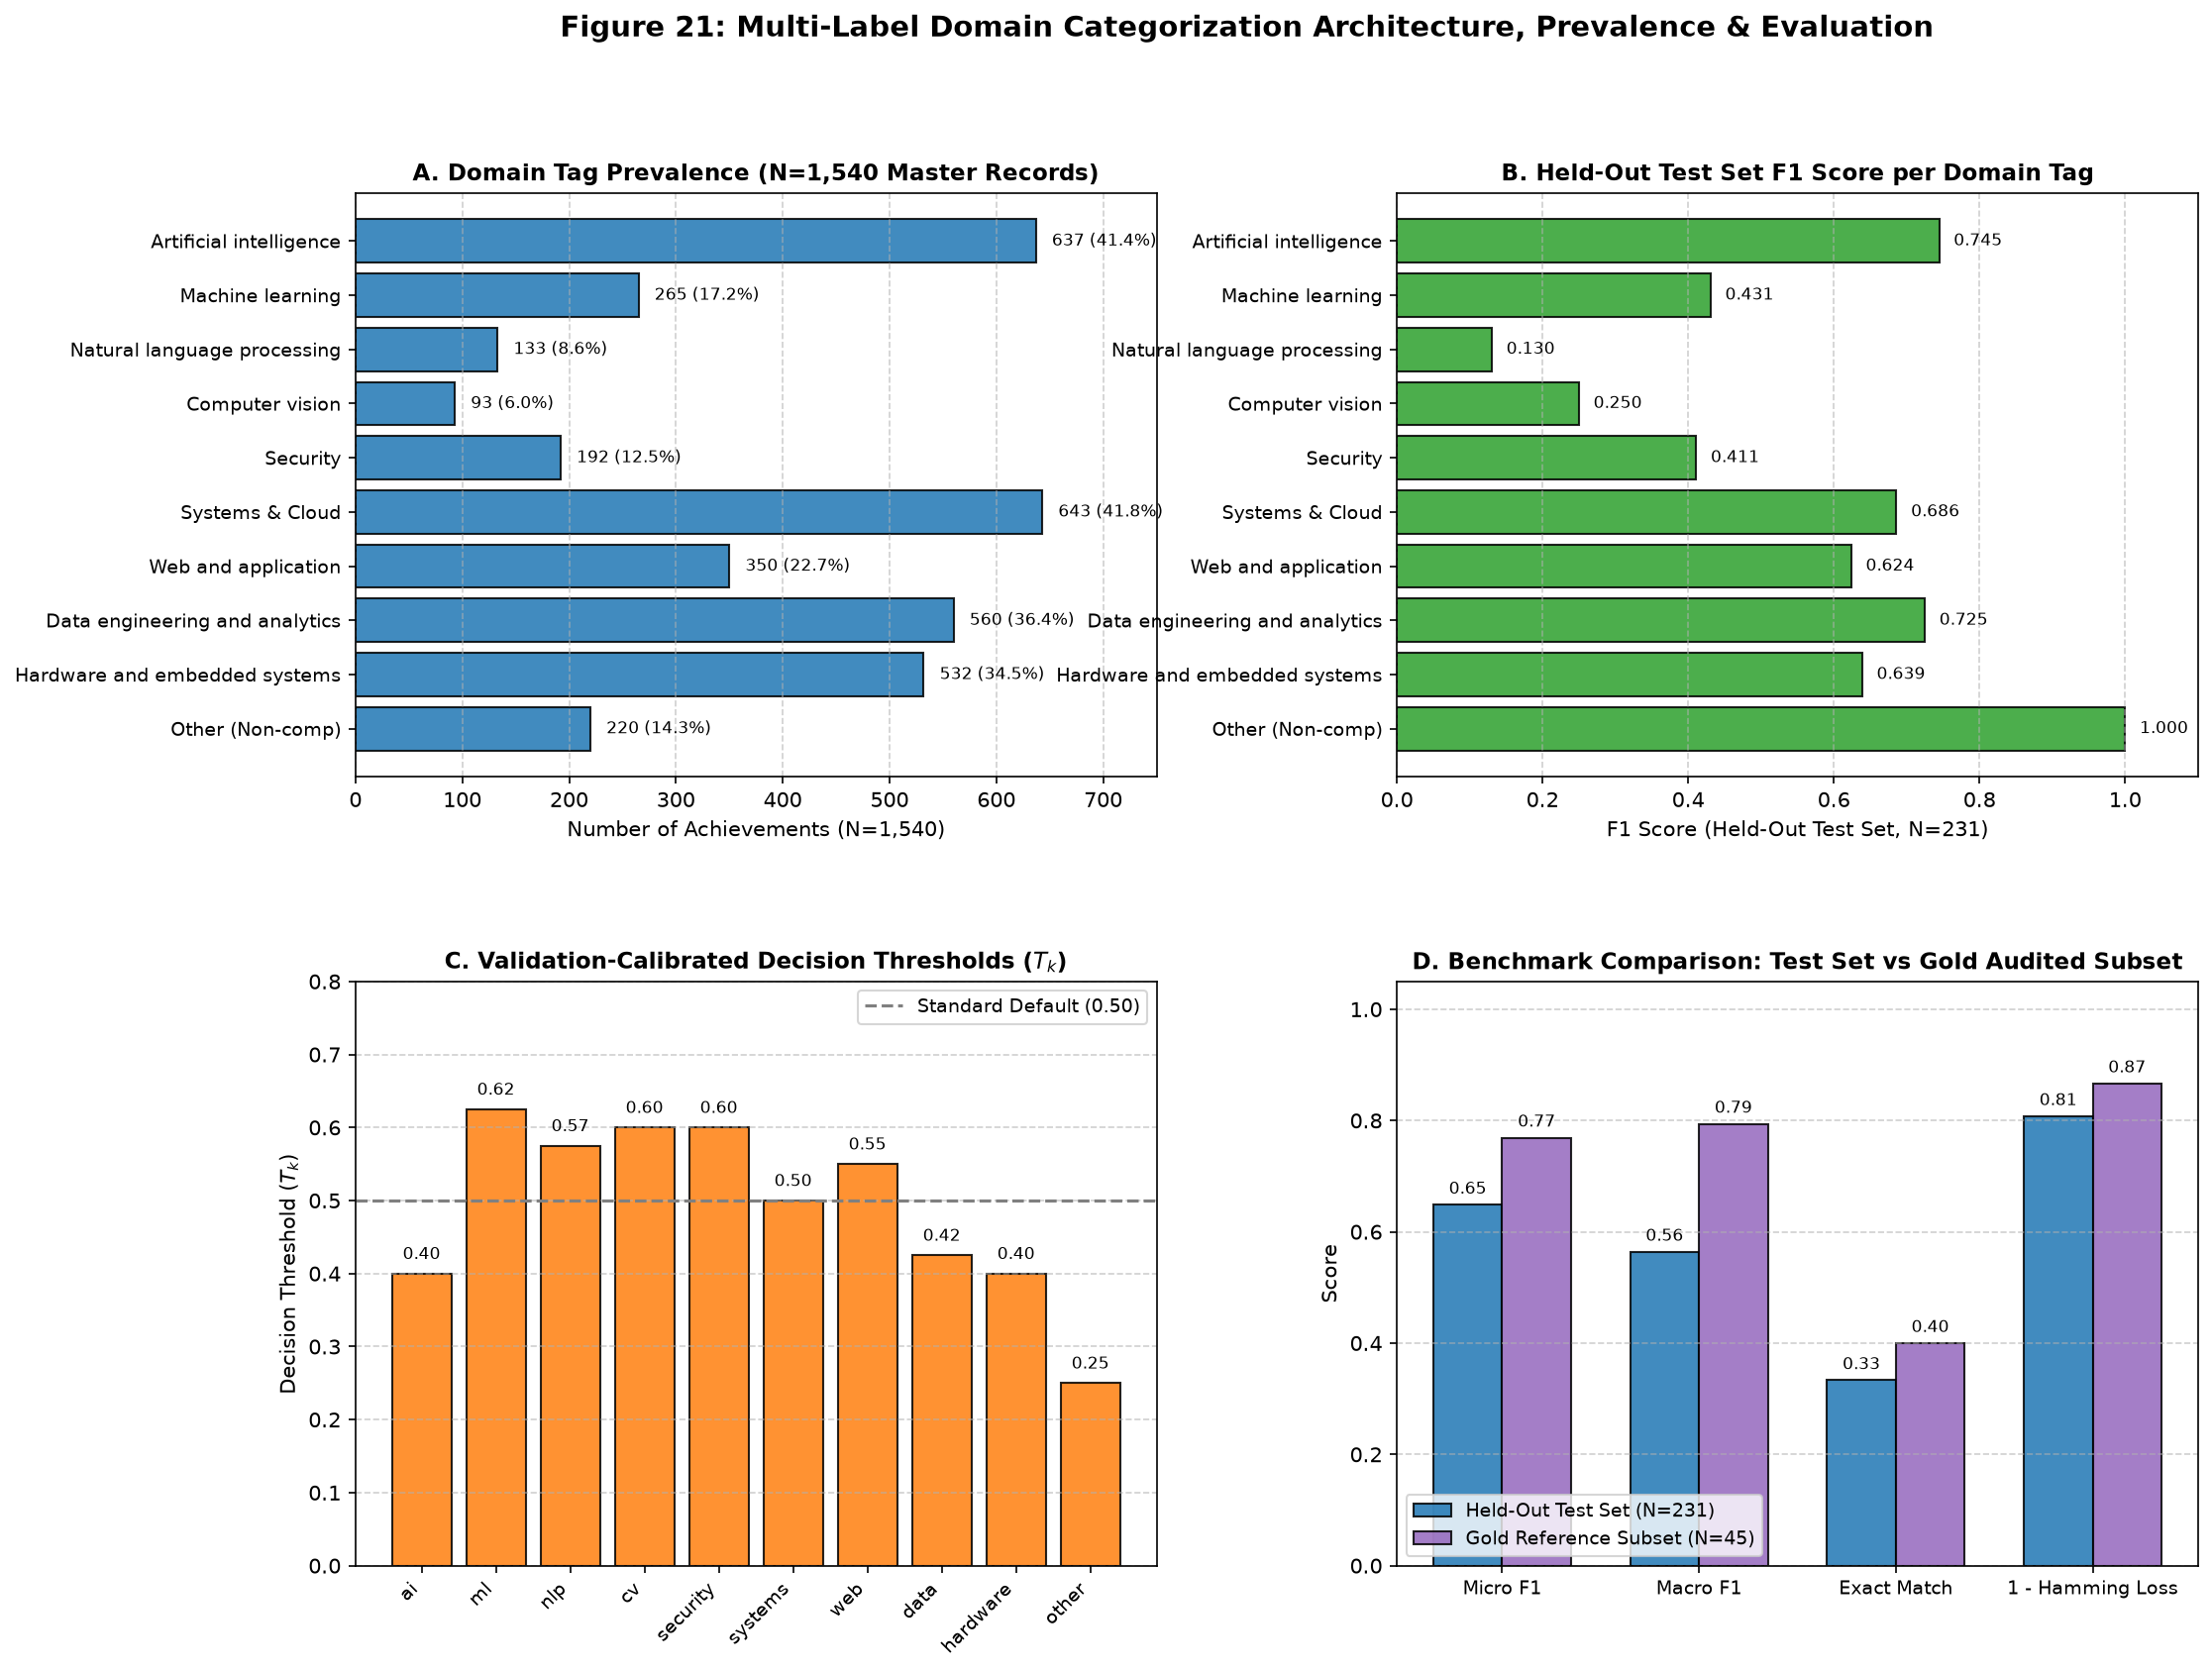

In [7]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.30)

# Colors
primary_color = "#1f77b4"
accent_color = "#ff7f0e"
teal_color = "#2ca02c"
purple_color = "#9467bd"

tag_labels_short = [DOMAIN_TAG_NAMES[t].replace("Other domain (Non-computing)", "Other (Non-comp)") for t in DOMAIN_TAGS]

# Panel A: Tag Prevalence across 1,540 Records
counts = [int(df[f"tag_{t}"].sum()) for t in DOMAIN_TAGS]
y_pos = np.arange(len(DOMAIN_TAGS))
axes[0, 0].barh(y_pos, counts, color=primary_color, alpha=0.85, edgecolor="black")
axes[0, 0].set_yticks(y_pos)
axes[0, 0].set_yticklabels(tag_labels_short, fontsize=9)
axes[0, 0].invert_yaxis()
axes[0, 0].set_xlabel("Number of Achievements (N=1,540)", fontsize=10)
axes[0, 0].set_title("A. Domain Tag Prevalence (N=1,540 Master Records)", fontsize=11, fontweight="bold")
axes[0, 0].grid(axis="x", linestyle="--", alpha=0.6)
for i, v in enumerate(counts):
    pct = (v / 1540.0) * 100.0
    axes[0, 0].text(v + 15, i, f"{v} ({pct:.1f}%)", va="center", fontsize=8)
axes[0, 0].set_xlim(0, 750)

# Panel B: Test Split F1 Score per Tag
f1_scores = [df_metrics.loc[df_metrics["Tag"] == t, "F1"].values[0] for t in DOMAIN_TAGS]
bars_b = axes[0, 1].barh(y_pos, f1_scores, color=teal_color, alpha=0.85, edgecolor="black")
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(tag_labels_short, fontsize=9)
axes[0, 1].invert_yaxis()
axes[0, 1].set_xlabel("F1 Score (Held-Out Test Set, N=231)", fontsize=10)
axes[0, 1].set_title("B. Held-Out Test Set F1 Score per Domain Tag", fontsize=11, fontweight="bold")
axes[0, 1].grid(axis="x", linestyle="--", alpha=0.6)
for i, v in enumerate(f1_scores):
    axes[0, 1].text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=8)
axes[0, 1].set_xlim(0, 1.1)

# Panel C: Validation-Calibrated Decision Thresholds
thresholds = [categorizer.thresholds[t] for t in DOMAIN_TAGS]
axes[1, 0].bar(np.arange(len(DOMAIN_TAGS)), thresholds, color=accent_color, alpha=0.85, edgecolor="black")
axes[1, 0].set_xticks(np.arange(len(DOMAIN_TAGS)))
axes[1, 0].set_xticklabels([t.replace("lbl_domain_", "") for t in DOMAIN_TAGS], rotation=45, ha="right", fontsize=9)
axes[1, 0].axhline(0.50, color="gray", linestyle="--", linewidth=1.5, label="Standard Default (0.50)")
axes[1, 0].set_ylabel("Decision Threshold ($T_k$)", fontsize=10)
axes[1, 0].set_title("C. Validation-Calibrated Decision Thresholds ($T_k$)", fontsize=11, fontweight="bold")
axes[1, 0].legend(loc="upper right", fontsize=9)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.6)
axes[1, 0].set_ylim(0, 0.8)
for i, v in enumerate(thresholds):
    axes[1, 0].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)

# Panel D: Benchmark Comparison: Test Set vs Gold Reference Subset
metrics_names = ["Micro F1", "Macro F1", "Exact Match", "1 - Hamming Loss"]
test_vals = [micro_f1, macro_f1, exact_match, 1.0 - h_loss]
gold_vals = [gold_micro_f1, gold_macro_f1, gold_exact_match, 1.0 - gold_h_loss]

x = np.arange(len(metrics_names))
width = 0.35
axes[1, 1].bar(x - width/2, test_vals, width, label="Held-Out Test Set (N=231)", color=primary_color, alpha=0.85, edgecolor="black")
axes[1, 1].bar(x + width/2, gold_vals, width, label="Gold Reference Subset (N=45)", color=purple_color, alpha=0.85, edgecolor="black")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(metrics_names, fontsize=9)
axes[1, 1].set_ylabel("Score", fontsize=10)
axes[1, 1].set_title("D. Benchmark Comparison: Test Set vs Gold Audited Subset", fontsize=11, fontweight="bold")
axes[1, 1].legend(loc="lower left", fontsize=9)
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.6)
axes[1, 1].set_ylim(0, 1.05)

for i in x:
    axes[1, 1].text(i - width/2, test_vals[i] + 0.02, f"{test_vals[i]:.2f}", ha="center", fontsize=8)
    axes[1, 1].text(i + width/2, gold_vals[i] + 0.02, f"{gold_vals[i]:.2f}", ha="center", fontsize=8)

plt.suptitle("Figure 21: Multi-Label Domain Categorization Architecture, Prevalence & Evaluation", fontsize=14, fontweight="bold", y=0.98)

## 8. Interactive Multi-Label Inference Demonstration
Demonstrate live inference across distinct scenarios:
1. Multi-disciplinary achievement (AI + Computer Vision + Systems)
2. Cybersecurity and Systems achievement
3. Non-computing / Cultural achievement (`lbl_domain_other`)
4. Completely empty or uninformative text (0 tags assigned)

In [8]:
demo_samples = [
    ("Scenario 1: AI, Vision & Systems", "Designed an edge AI drone object detection model using YOLOv8 and TensorRT with high throughput RTSP streaming."),
    ("Scenario 2: Security & Cloud", "Achieved AWS Certified Security Specialist credential demonstrating expertise in IAM hardening, KMS encryption, and threat detection."),
    ("Scenario 3: Non-computing Domain", "Awarded Trophy of Excellence at the All India Inter-University Debating Championship on Parliamentary Governance."),
    ("Scenario 4: Empty Text", ""),
]

print("=== LIVE MULTI-LABEL INFERENCE DEMONSTRATION ===")
for label, text in demo_samples:
    res = categorizer.predict_record(text)
    tags_str = ", ".join([f"{t} ({DOMAIN_TAG_NAMES[t]})" for t in res.predicted_tags]) if res.predicted_tags else "None (0 domain tags assigned)"
    print(f"\n[{label}]")
    print(f"  Input Text: \"{text}\"")
    print(f"  Assigned Tags: {tags_str}")
    top_scores = sorted(res.tag_scores.items(), key=lambda kv: kv[1], reverse=True)[:3]
    top_scores_str = ", ".join([f"{k.replace('lbl_domain_', '')}: {v:.3f} (thresh={res.thresholds[k]:.2f})" for k, v in top_scores])
    print(f"  Top Tag Scores: {top_scores_str}")

=== LIVE MULTI-LABEL INFERENCE DEMONSTRATION ===

[Scenario 1: AI, Vision & Systems]
  Input Text: "Designed an edge AI drone object detection model using YOLOv8 and TensorRT with high throughput RTSP streaming."
  Assigned Tags: lbl_domain_ai (Artificial intelligence), lbl_domain_systems (Systems & Cloud), lbl_domain_data (Data engineering and analytics), lbl_domain_hardware (Hardware and embedded systems)
  Top Tag Scores: ai: 0.715 (thresh=0.40), systems: 0.619 (thresh=0.50), hardware: 0.585 (thresh=0.40)

[Scenario 2: Security & Cloud]
  Input Text: "Achieved AWS Certified Security Specialist credential demonstrating expertise in IAM hardening, KMS encryption, and threat detection."
  Assigned Tags: lbl_domain_systems (Systems & Cloud), lbl_domain_hardware (Hardware and embedded systems)
  Top Tag Scores: systems: 0.630 (thresh=0.50), security: 0.532 (thresh=0.60), hardware: 0.523 (thresh=0.40)

[Scenario 3: Non-computing Domain]
  Input Text: "Awarded Trophy of Excellence at the A

## 9. Integration Verification & Member 2 Handoff
Verify that the `NLPEvidencePipeline` successfully surfaces `domain_tags` and `categorization`
alongside single-label `classification` without schema breakage.

In [9]:
from src.nlp.pipeline import get_nlp_pipeline

pipeline = get_nlp_pipeline()
sample_doc = (
    "Certificate of Excellence: Awarded to Rohan Verma for successfully completing "
    "the Full Stack Cloud Application Development Capstone on Google Cloud Platform, "
    "building microservices in Go and frontend in React with CI/CD pipelines."
)
pipeline_res = pipeline.process_text(sample_doc, document_id="DEMO-STEP10-001")

print("=== PIPELINE PROCESSING CONTRACT VERIFICATION ===")
print(f"Document ID:             {pipeline_res.document_id}")
print(f"Primary Category:        {pipeline_res.classification['predicted_category']} (Confidence: {pipeline_res.classification['confidence']:.2f})")
print(f"Multi-Label Domain Tags: {pipeline_res.domain_tags}")
print(f"Field Confidence:        {pipeline_res.field_confidence:.4f}")
print(f"Overall Confidence:      {pipeline_res.overall_confidence:.4f}")
print(f"Status:                  {pipeline_res.status}")

# Verify serialization keys
contract_dict = pipeline_res.to_dict()
assert "classification" in contract_dict
assert "domain_tags" in contract_dict
assert "categorization" in contract_dict
print("\n[OK] Pipeline processing contract verified with full multi-label integration.")

=== PIPELINE PROCESSING CONTRACT VERIFICATION ===
Document ID:             DEMO-STEP10-001
Primary Category:        CERTIFICATION (Confidence: 0.12)
Multi-Label Domain Tags: ['lbl_domain_systems', 'lbl_domain_web']
Field Confidence:        0.4369
Overall Confidence:      0.3106
Status:                  REVIEW_REQUIRED

[OK] Pipeline processing contract verified with full multi-label integration.
